In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:38511")
client

<Client: 'tcp://127.0.0.1:38511' processes=10 threads=40, memory=629.62 GiB>

In [4]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [5]:
H = xr.open_zarr(op.join(ddir,"SW/bathy.zarr")).H

for pp in range(6,9):
    if pp == 6:
        ds = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256})
    else:
        tmp = xr.open_dataset(op.join(ddir,"SW/vars_4096_p%1d.nc" % pp)
                            ).isel(time=slice(1,None),
                                   level=slice(None,None)
                                  ).chunk({"time":1,"level":-1,"y":128,"x":256}
                                         )
        time = tmp.time.data + ds.time[-1].data
        tmp = tmp.reset_index("time", drop=False)
        tmp = tmp.reset_coords("time", drop=True)
        tmp.coords["time"] = ("time", time)
        ds = xr.concat([ds, tmp], "time")
        tmp.close()
    
ds

<xarray.Dataset> Size: 317GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>

[2.13 3.85 5.26 6.27] <xarray.DataArray (lp1: 4)> Size: 32B
array([1002.13, 1001.72, 1001.41, 1001.01])
Coordinates:
  * lp1      (lp1) float64 32B 0.5 1.5 2.5 3.5
Fitted Equation: y = 0.0118 * e^(0.2000 * x) + -0.0334


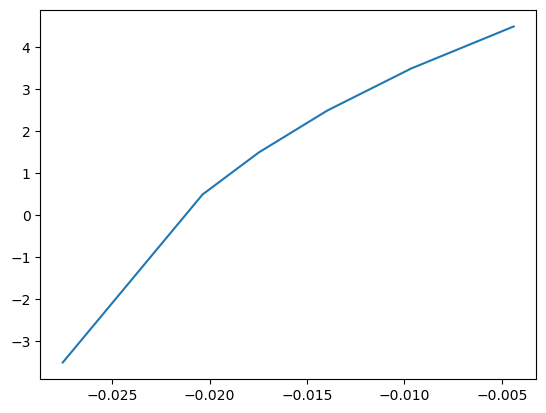

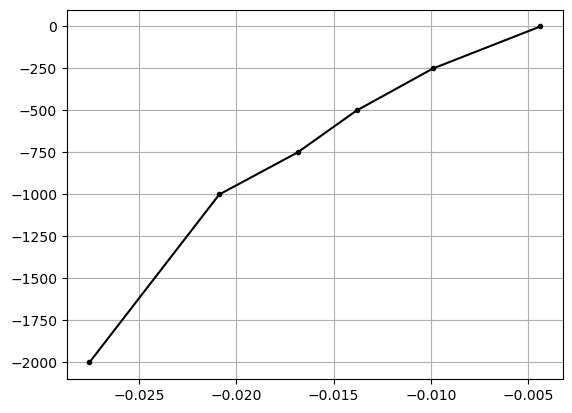

<xarray.Dataset> Size: 550GB
Dimensions:  (time: 630, level: 5, y: 2048, x: 4096, lp1: 6)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
Data variables:
    h        (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.x      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    u.y      (time, level, y, x) float32 106GB dask.array<chunksize=(1, 5, 128, 256), meta=np.ndarray>
    Z        (time, level, y, x) float32 106GB dask.array<chunksize=(4, 5, 128, 256), meta=np.ndarray>
    Zp1      (time, lp1, y, x) float32 127GB dask.array<chunksize=(4, 6, 128, 256), meta=np.ndarray>
    b        (lp1) float64 48B -0.02754 -0.02087 ... -0.009898 -0.004391

In [6]:
rho0 = 1e3
drho = np.array([2.13, 1.72, 1.41, 1.01,])
rho = xr.DataArray(drho + rho0, 
                   dims="lp1",
                   coords={"lp1":np.array([0.5,1.5,2.5,3.5])}
                  )
print(np.cumsum(drho), rho)

# log_y = np.log(rho)

# # 2. Fit a 1st-degree polynomial (linear fit: y = mx + c)
# # Returns [B, ln(A)]
# coefficients = np.polyfit(rho.lp1.data, log_y, 1)

# # 3. Extract the parameters
# B = coefficients[0]
# A = np.exp(coefficients[1])

# print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x)")

# rp1 = np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5)),]),rho.data)),
#                     np.array([A*np.exp(B*(4.5)),]) 
#                    ))

b = -9.8*(rho - rho0) / rho0

B = 0.2
def exp_func(x, a, c):
    return a * np.exp(B * x) + c

initial_guess = [1, -1e-2]
popt, pcov = curve_fit(exp_func, b.lp1.values, b.values, p0=initial_guess)

# 3. Extract parameters
A, C = popt
print(f"Fitted Equation: y = {A:.4f} * e^({B:.4f} * x) + {C:.4f}")
plt.plot(A*np.exp(B*np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))+C, 
         np.array([-3.5,0.5,1.5,2.5,3.5,4.5]))
plt.show()

bp1 = xr.DataArray(np.concatenate((np.concatenate((np.array([A*np.exp(B*(-3.5))+C,]),b.data)),
                    np.array([A*np.exp(B*(4.5))+C,]) 
                   )), dims="lp1", 
                   coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                  )

ds2 = ds.copy()

ssh = xr.open_zarr(op.join(ddir,"SW/SSH.zarr")).ssh
dszl = xr.open_zarr(op.join(ddir,"SW/Zl.zarr"))
dsz = xr.open_zarr(op.join(ddir,"SW/Z.zarr"))
ds2["Z"] = dsz.Z.transpose("time","level","y","x").chunk({"level":-1})
Zp1 = xr.concat([dszl.Zl, xr.DataArray(ssh.data[:,:,:,np.newaxis],
                                    dims=dszl.Zl.dims, 
                                    coords={"lp1":np.array([4.5,])})
                ], "lp1")
ds2["Zp1"] = Zp1.transpose("time","lp1","y","x").chunk({"lp1":-1})
ds2["b"] = bp1

fig, ax = plt.subplots()
ax.plot(ds2.b, -np.array([2000,1000,750,500,250,0]), "k.-")
ax.grid(True)
plt.show()

ds2

In [7]:
dsb = xr.open_zarr(op.join(ddir,"SW/mean/UVh.zarr")
                  ).chunk({"level":1,"y":128,"x":256}
                         )
maskh = xr.DataArray(np.ma.masked_values(dsb.hbar.sum("level"),0.).mask,
                     dims=dsb.hbar.sum("level").dims, 
                     coords=dsb.hbar.sum("level").coords
                    )

In [8]:
ds2.coords["yG"] = ("yG",.5*(ds2.y.data[1:]+ds2.y.data[:-1]))
ds2.coords["xG"] = ("xG",.5*(ds2.x.data[1:]+ds2.x.data[:-1]))
# ds2.coords["ll"] = ("ll",np.arange(-.5,5,1.))
grid = Grid(ds2, periodic=None, autoparse_metadata=False,
            coords={'X': {"center": "x", "inner": "xG"},
                    'Y': {"center": "y", "inner": "yG"},
                    'Z': {"center": "level", "outer": "lp1"}
                   })
# grid_sub = Grid(ds2.isel(lp1=slice(1,-1)), periodic=None, 
#                 autoparse_metadata=False,
#             coords={'X': {"outer": "x", "inner": "xG"},
#                     'Y': {"outer": "y", "inner": "yG"},
#                     'Z': {"center": "level", "inner": "lp1"}
#                    })
grid

<xgcm.Grid>
X Axis (not periodic, boundary='fill'):
  * center   x --> inner
  * inner    xG --> center
Y Axis (not periodic, boundary='fill'):
  * center   y --> inner
  * inner    yG --> center
Z Axis (not periodic, boundary='fill'):
  * center   level --> outer
  * outer    lp1 --> center

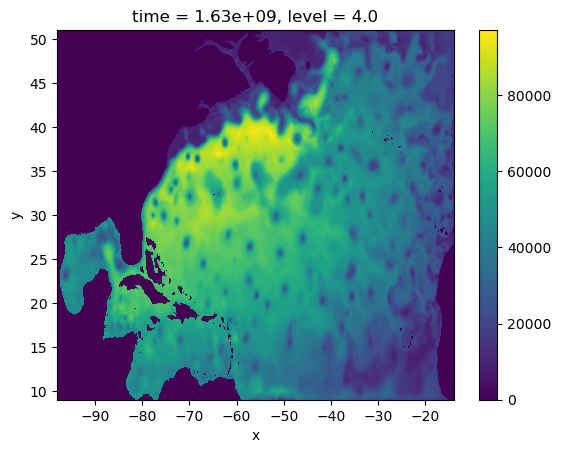

In [9]:
# sig = (ds2.h
#        / ds2.b.diff("lp1").dropna("lp1").data[np.newaxis,:,np.newaxis,np.newaxis]
#       )
sig = (ds2.h
       / grid.diff(ds2.b,"Z",boundary="extend")
      )
sig.isel(time=-1,level=-1).plot(rasterized=True)


In [10]:
llo, lla = np.meshgrid(ds.x, ds.y)
xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
                  coords={"y":ds.y.data,
                          "xG":.5*(ds.x.data[1:]+ds.x.data[:-1])}
                 )
yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
                  coords={"yG":.5*(ds.y.data[1:]+ds.y.data[:-1]),
                          "x":ds.x.data}
                 )

v_x = grid.interp(grid.diff(ds["u.y"].fillna(0.).chunk({"x":-1}), 
                            "X", boundary="extend"
                           ) / xxG, 
                  "X", boundary="extend")
u_y = grid.interp(grid.diff(ds["u.x"].fillna(0.).chunk({"y":-1}), 
                            "Y", boundary="extend"
                           ) / yyG, 
                  "Y", boundary="extend")

zz = -np.array([875,750,625,500,375,250,125])
u_yz = grid.transform(u_y, "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.chunk({"level":-1})
                   ).fillna(0.)
v_xz = grid.transform(v_x, "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.chunk({"level":-1})
                   ).fillna(0.)

z_b = grid.transform(sig.fillna(0.).chunk({"level":-1}), "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.chunk({"level":-1})
                   ).fillna(0.)
uz = grid.transform(ds2["u.x"].fillna(0.), "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.chunk({"level":-1})
                   ).fillna(0.)
vz = grid.transform(ds2["u.y"].fillna(0.), "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.chunk({"level":-1})
                   ).fillna(0.)

z_b

<xarray.DataArray (time: 630, y: 2048, x: 4096, Z: 7)> Size: 296GB
dask.array<where, shape=(630, 2048, 4096, 7), dtype=float64, chunksize=(1, 128, 256, 7), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * Z        (Z) int64 56B -875 -750 -625 -500 -375 -250 -125

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 34.96 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


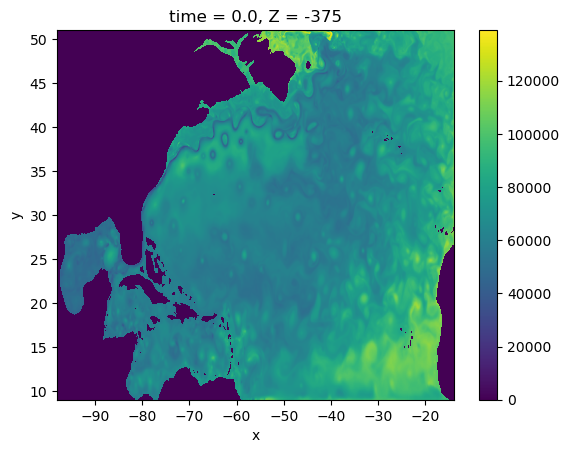

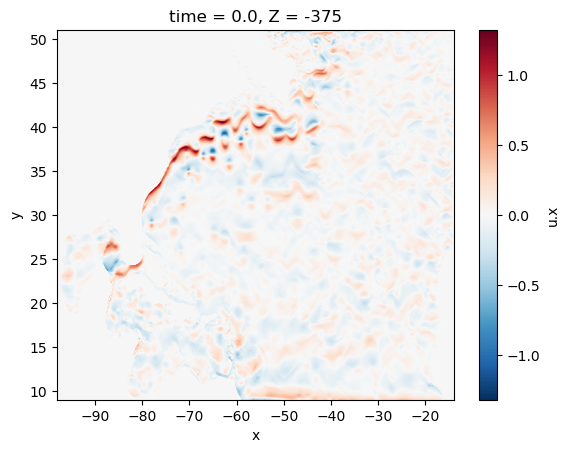

In [11]:
z_b.isel(Z=-3,time=0).plot(rasterized=True)
plt.show()
uz.isel(Z=-3,time=0).plot(rasterized=True)
plt.show()

In [12]:
dsave = uz.to_dataset(name="u")
dsave["v"] = vz
dsave["sig"] = z_b
dsave.chunk({"time":4,"Z":1,}).to_zarr(op.join(ddir,"SW/b-to-Z.zarr"), 
                                        mode="w")

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 533.90 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [13]:
dsave = u_yz.to_dataset(name="u_y")
dsave["v_x"] = v_xz
# dsave["sig"] = z_b
dsave.chunk({"time":4,"Z":1,}).to_zarr(op.join(ddir,"SW/UyVx_b-to-Z.zarr"), 
                                       mode="w")

/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 550.31 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [15]:
dsbz = xr.open_zarr(op.join(ddir,"SW/b-to-Z.zarr")
                   ).chunk({"time":4,"Z":1})
print(dsbz)
dsave = dsbz.u.mean("time").to_dataset(name="ub")
dsave["vb"] = dsbz.v.mean("time")
dsave["sigb"] = dsbz.sig.mean("time")
dsave.to_zarr(op.join(ddir,"SW/mean/b-to-Z.zarr"), mode="w")

<xarray.Dataset> Size: 592GB
Dimensions:  (time: 630, y: 2048, x: 4096, Z: 7)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * Z        (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    sig      (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    u        (time, y, x, Z) float32 148GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    v        (time, y, x, Z) float32 148GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 20.95 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [16]:
dsbz = xr.open_zarr(op.join(ddir,"SW/UyVx_b-to-Z.zarr")
                   ).chunk({"time":4,"Z":1})
print(dsbz)
dsave = dsbz.u_y.mean("time").to_dataset(name="ub_y")
dsave["vb_x"] = dsbz.v_x.mean("time")
dsave.to_zarr(op.join(ddir,"SW/mean/UyVx_b-to-Z.zarr"), mode="w")

<xarray.Dataset> Size: 592GB
Dimensions:  (time: 630, y: 2048, x: 4096, Z: 7)
Coordinates:
  * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * Z        (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    u_y      (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    v_x      (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 13.97 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [17]:
dsPib = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/InB.zarr")
                    ).transpose("time","level","y","x"
                               ).chunk({"time":1,"level":-1})

zz = -np.array([875,750,625,500,375,250,125])
Pif = grid.transform(dsPib.Piflat.fillna(0.), "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.isel(level=slice(1,None)
                                          ).chunk({"level":-1})
                   ).fillna(0.)
Pip = grid.transform(dsPib.Pip.fillna(0.), "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.isel(level=slice(1,None)
                                          ).chunk({"level":-1})
                   ).fillna(0.)
Pid = grid.transform(dsPib.Pidagger.fillna(0.).chunk({"level":-1}), "Z", 
                    zz,
                    method="linear",
                    target_data=ds2.Z.isel(level=slice(1,None)
                                          ).chunk({"level":-1})
                   ).fillna(0.)
Pif, Pip, Pid

(<xarray.DataArray 'Piflat' (time: 630, y: 2048, x: 4096, Z: 7)> Size: 296GB
 dask.array<where, shape=(630, 2048, 4096, 7), dtype=float64, chunksize=(1, 128, 256, 7), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * Z        (Z) int64 56B -875 -750 -625 -500 -375 -250 -125,
 <xarray.DataArray 'Pip' (time: 630, y: 2048, x: 4096, Z: 7)> Size: 296GB
 dask.array<where, shape=(630, 2048, 4096, 7), dtype=float64, chunksize=(1, 128, 256, 7), chunktype=numpy.ndarray>
 Coordinates:
   * time     (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
   * y        (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
   * x        (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
   * Z        (Z) int64 56B -875 -750 -625 -500 -37

In [18]:
dsave = Pif.to_dataset(name="Piflat")
dsave["Pip"] = Pip
dsave["Pidagger"] = Pid
print(dsave)
dsave.chunk({"time":4,"Z":1,"y":128,"x":256}
           ).to_zarr(op.join(ddir,"SW/TWA/eddyPi/b-to-Z.zarr"),
                     mode="w")

<xarray.Dataset> Size: 888GB
Dimensions:   (time: 630, x: 4096, y: 2048, Z: 7)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * Z         (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    Piflat    (time, y, x, Z) float64 296GB dask.array<chunksize=(1, 128, 256, 7), meta=np.ndarray>
    Pip       (time, y, x, Z) float64 296GB dask.array<chunksize=(1, 128, 256, 7), meta=np.ndarray>
    Pidagger  (time, y, x, Z) float64 296GB dask.array<chunksize=(1, 128, 256, 7), meta=np.ndarray>


/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/zarr/api/asynchronous.py:231: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/storage/tartar/takaya/miniconda3/envs/basil/lib/python3.12/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 701.75 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


In [19]:
dsPiz = xr.open_zarr(op.join(ddir,"SW/TWA/eddyPi/b-to-Z.zarr"))
dsPiz

<xarray.Dataset> Size: 888GB
Dimensions:   (time: 630, y: 2048, x: 4096, Z: 7)
Coordinates:
  * time      (time) float32 3kB 0.0 2.592e+06 5.184e+06 ... 1.628e+09 1.63e+09
  * y         (y) float32 8kB 9.01 9.031 9.051 9.072 ... 50.93 50.95 50.97 50.99
  * x         (x) float32 16kB -97.99 -97.97 -97.95 ... -14.05 -14.03 -14.01
  * Z         (Z) int64 56B -875 -750 -625 -500 -375 -250 -125
Data variables:
    Pidagger  (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    Piflat    (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>
    Pip       (time, y, x, Z) float64 296GB dask.array<chunksize=(4, 128, 256, 1), meta=np.ndarray>

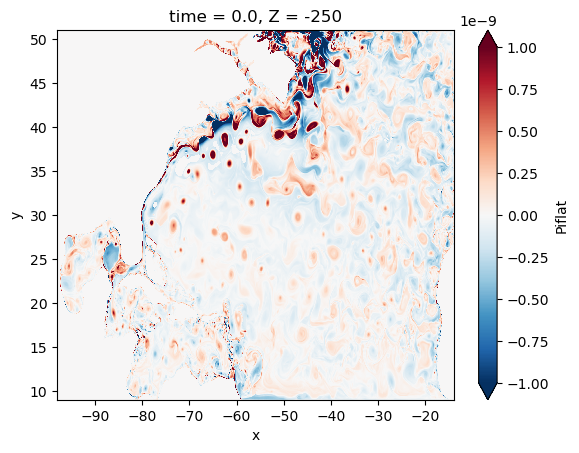

In [20]:
dsPiz.Piflat.isel(time=0,Z=-2).plot(vmax=1e-9, rasterized=True)

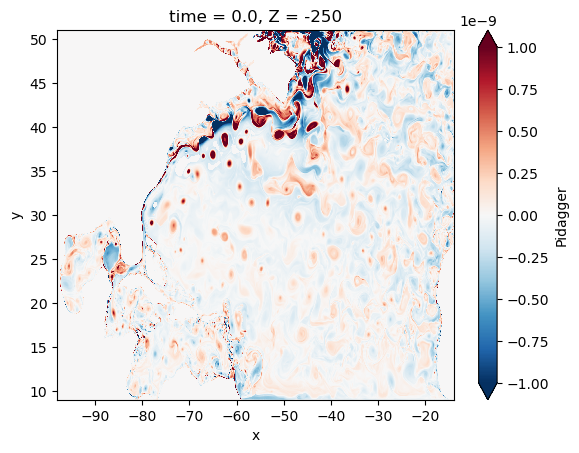

In [21]:
dsPiz.Pidagger.isel(time=0,Z=-2).plot(vmax=1e-9, rasterized=True)

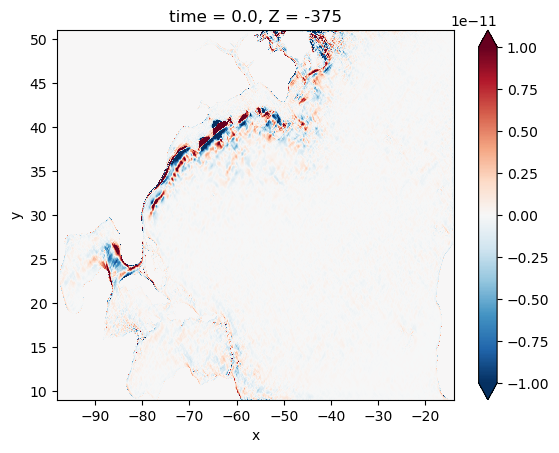

In [22]:
(dsPiz.Piflat - dsPiz.Pidagger
).isel(time=0,Z=-3).plot(vmax=1e-11, rasterized=True)

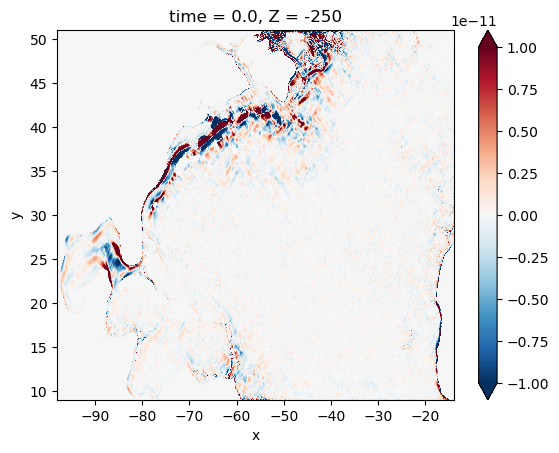

In [23]:
(dsPiz.Piflat - dsPiz.Pidagger
).isel(time=0,Z=-2).plot(vmax=1e-11, rasterized=True)